# Q

Consider the dataset insurance.csv in Cases/Medical_Cost_personal folder
Build Linear Regression and Regularized Regression Algorithms and find the best model based on R2

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import make_column_selector, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

## Linear Regression

In [2]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Medical_Cost_personal\insurance.csv")
df.sample(5)

,age,sex,bmi,children,smoker,region,charges
821,26,male,17.670,0,no,northwest,2680.94930
1022,47,male,36.080,1,yes,southeast,42211.13820
422,40,male,32.775,1,yes,northeast,39125.33225
827,36,male,28.025,1,yes,northeast,20773.62775
1229,58,male,30.305,0,no,northeast,11938.25595


In [3]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [4]:
X , y = df.drop('charges',axis=1) , df['charges']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)

In [5]:
encoder = OneHotEncoder(sparse_output=False, drop='first')

ct = make_column_transformer((encoder,make_column_selector(dtype_include='object')),
                             ('passthrough',make_column_selector(dtype_include='number')),
                             verbose_feature_names_out = False)
scaler = StandardScaler()

In [6]:
lr = LinearRegression()
pipe = Pipeline([('OHE',ct),('SCL',scaler),('LR',lr)])
pipe.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OHE', ...), ('SCL', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehotencoder', ...), ('passthrough', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will erro

In [7]:
best_model = {'Model':['Linear Regression','Ridge Regression'],
             'R2 Score':[]}

In [8]:
y_pred = pipe.predict(X_test)
best_model['R2 Score'].append(r2_score(y_test,y_pred))
print('R2 Score ->',r2_score(y_test,y_pred))

R2 Score -> 0.7625873682287876


# Ridge Regression

In [9]:
alpha = np.linspace(0.001,20,20)
score = []
for x in alpha:
    rdg = Ridge(alpha=x)
    pipe = Pipeline([('OHE',ct),('SCL',scaler),('LR',rdg)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    
    score.append([x,r2_score(y_test,y_pred)])
df_score = pd.DataFrame(score,columns=['X','R2 Score']).sort_values('R2 Score',ascending=False)
best_model['R2 Score'].append(df_score['R2 Score'].iloc[0].item())
df_score.head()

,X,R2 Score
0,0.001000,0.762587
1,1.053579,0.762535
2,2.106158,0.762480
3,3.158737,0.762424
4,4.211316,0.762366


In [10]:
models = pd.DataFrame(best_model)
models.sort_values('R2 Score',ascending=False)

,Model,R2 Score
0,Linear Regression,0.762587
1,Ridge Regression,0.762587


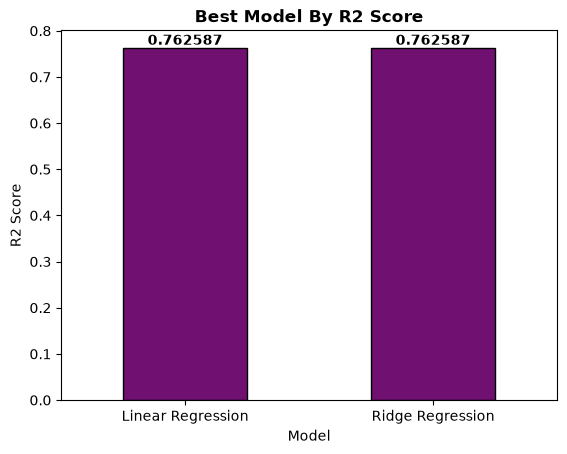

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

bars = sns.barplot(x=models.Model,y=models['R2 Score'],edgecolor='black',width=0.5,color='purple')
plt.title('Best Model By R2 Score', fontweight='bold')
ax = plt.gca()
ax.bar_label(ax.containers[0],fontweight='bold')
plt.show()